# Delhi-NCR Air Quality — Exploratory Data Analysis

This notebook loads our historical AQI data from `data/aqi_history.db`, performs
basic cleaning, and generates summary statistics and visualisations.

## 1. Setup & Imports

In [24]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Style settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

# Database path (relative to notebooks/ folder)
DB_PATH = os.path.join("..", "data", "aqi_history.db")
print(f"Database path: {os.path.abspath(DB_PATH)}")

Database path: c:\Users\tanis\OneDrive\Documents\Delhi-NCR Air Quality Forecasting\data\aqi_history.db


## 2. Load Data from SQLite

In [25]:
conn = sqlite3.connect(DB_PATH)
df = pd.read_sql("SELECT * FROM aqi_readings", conn)
conn.close()

print(f"Loaded {len(df):,} rows and {len(df.columns)} columns.")
df.sample

Loaded 280,340 rows and 5 columns.


<bound method NDFrame.sample of             id                                           station  \
0            3                                 ITO, Delhi - CPCB   
1            4                              Narela, Delhi - DPCC   
2            5                     Cantonment Area, Delhi - DPCC   
3            6  Major Dhyan Chand National Stadium, Delhi - DPCC   
4            7                         Sonia Vihar, Delhi - DPCC   
...        ...                                               ...   
280335  280338               Faridabad New Town, Haryana - HSPCB   
280336  280339               Faridabad New Town, Haryana - HSPCB   
280337  280340               Faridabad New Town, Haryana - HSPCB   
280338  280341               Faridabad New Town, Haryana - HSPCB   
280339  280342               Faridabad New Town, Haryana - HSPCB   

                last_update pollutant_id  avg_value  
0       25-08-2026 01:00:00           CO       83.0  
1       25-08-2026 01:00:00        PM2.5   

## 3. Initial Shape & Summary Statistics

In [26]:
print(f"Shape: {df.shape}")
print()
df.info()

Shape: (280340, 5)

<class 'pandas.DataFrame'>
RangeIndex: 280340 entries, 0 to 280339
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            280340 non-null  int64  
 1   station       280340 non-null  str    
 2   last_update   280340 non-null  str    
 3   pollutant_id  280340 non-null  str    
 4   avg_value     274632 non-null  float64
dtypes: float64(1), int64(1), str(3)
memory usage: 10.7 MB


In [27]:
df.describe()

,id,avg_value
count,280340.00000,274632.000000
mean,140172.50000,71.886257
std,80927.33157,67.661971
min,3.00000,2.000000
25%,70087.75000,25.000000
50%,140172.50000,52.500000
75%,210257.25000,96.800000
max,280342.00000,449.900000


In [28]:
dup_cols = ["station", "last_update", "pollutant_id"]
n_before = len(df)
n_dupes = df.duplicated(subset=dup_cols).sum()
print(f"Duplicate rows found: {n_dupes:,}")

df = df.drop_duplicates(subset=dup_cols, keep="first").reset_index(drop=True)
print(f"Rows after dedup: {len(df):,}  (removed {n_before - len(df):,})")

Duplicate rows found: 140,160
Rows after dedup: 140,180  (removed 140,160)


## 5. Convert `last_update` to Datetime

In [29]:
df["last_update"] = pd.to_datetime(df["last_update"], format="%d-%m-%Y %H:%M:%S", errors="coerce")
print(f"Date range: {df['last_update'].min()} → {df['last_update'].max()}")
df.dtypes

Date range: 2025-08-25 00:00:00 → 2026-08-25 17:00:00


id                       int64
station                    str
last_update     datetime64[us]
pollutant_id               str
avg_value              float64
dtype: object

## 6. Summary Insights

### 6a. Unique Monitoring Stations

In [30]:
stations = sorted(df["station"].unique())
print(f"Total unique stations: {len(stations)}\n")
for i, s in enumerate(stations, 1):
    print(f"  {i:>2}. {s}")

Total unique stations: 23

   1. Anand Vihar, Delhi - DPCC
   2. Bawana, Delhi - DPCC
   3. Cantonment Area, Delhi - DPCC
   4. DTU, Delhi - CPCB
   5. Faridabad New Town, Haryana - HSPCB
   6. Ghaziabad Vasundhara, UP - CPCB
   7. Greater Noida, UP - CPCB
   8. Gurugram Teri Gram, Haryana - HSPCB
   9. IGI Airport T3, Delhi - IMD
  10. ITO, Delhi - CPCB
  11. Major Dhyan Chand National Stadium, Delhi - DPCC
  12. Mandir Marg, Delhi - DPCC
  13. Mundka, Delhi - DPCC
  14. Narela, Delhi - DPCC
  15. Nehru Nagar, Delhi - DPCC
  16. Noida Sector 62, UP - CPCB
  17. Okhla Phase-2, Delhi - DPCC
  18. Punjabi Bagh, Delhi - DPCC
  19. R K Puram, Delhi - DPCC
  20. Rohini, Delhi - DPCC
  21. Shadipur, Delhi - CPCB
  22. Sonia Vihar, Delhi - DPCC
  23. Sri Aurobindo Marg, Delhi - DPCC


### 6b. Unique Pollutants

In [31]:
pollutants = sorted(df["pollutant_id"].unique())
print(f"Total unique pollutants: {len(pollutants)}\n")
for p in pollutants:
    count = len(df[df["pollutant_id"] == p])
    print(f"  • {p:<8} — {count:>7,} readings")

Total unique pollutants: 8

  • CO       —  23,363 readings
  • NH3      —       1 readings
  • NO2      —  23,364 readings
  • O3       —  23,360 readings
  • OZONE    —       1 readings
  • PM10     —  23,363 readings
  • PM2.5    —  23,363 readings
  • SO2      —  23,365 readings


### 6c. Missing Value Counts

In [32]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_%": missing_pct})

,missing_count,missing_%
id,0,0.00
station,0,0.00
last_update,0,0.00
pollutant_id,0,0.00
avg_value,2846,2.03


### 6d. Average Pollutant Levels by Station

In [33]:
avg_by_station = (
    df.groupby(["station", "pollutant_id"])["avg_value"]
    .mean()
    .round(2)
    .unstack(fill_value=0)
)
avg_by_station

pollutant_id,CO,NH3,NO2,O3,OZONE,PM10,PM2.5,SO2
station,,,,,,,,
"Anand Vihar, Delhi - DPCC",79.68,0.0,50.02,47.34,0.0,160.36,79.27,12.41
"Bawana, Delhi - DPCC",31.00,0.0,0.00,0.00,0.0,0.00,123.00,13.00
"Cantonment Area, Delhi - DPCC",0.00,0.0,12.00,0.00,0.0,0.00,0.00,5.00
"DTU, Delhi - CPCB",80.50,0.0,49.74,47.07,0.0,163.55,78.30,12.74
"Faridabad New Town, Haryana - HSPCB",78.10,0.0,49.94,47.70,0.0,162.93,79.12,12.49
"Ghaziabad Vasundhara, UP - CPCB",79.68,0.0,49.73,47.59,0.0,161.63,79.09,12.47
"Greater Noida, UP - CPCB",80.31,0.0,50.48,46.96,0.0,164.60,80.24,12.84
"Gurugram Teri Gram, Haryana - HSPCB",79.56,0.0,49.50,47.39,0.0,165.10,79.48,12.66
"IGI Airport T3, Delhi - IMD",79.39,0.0,50.64,47.09,0.0,161.04,80.25,12.71


## 7. Visualisations

### 7a. Average PM2.5 by Station (Bar Chart)

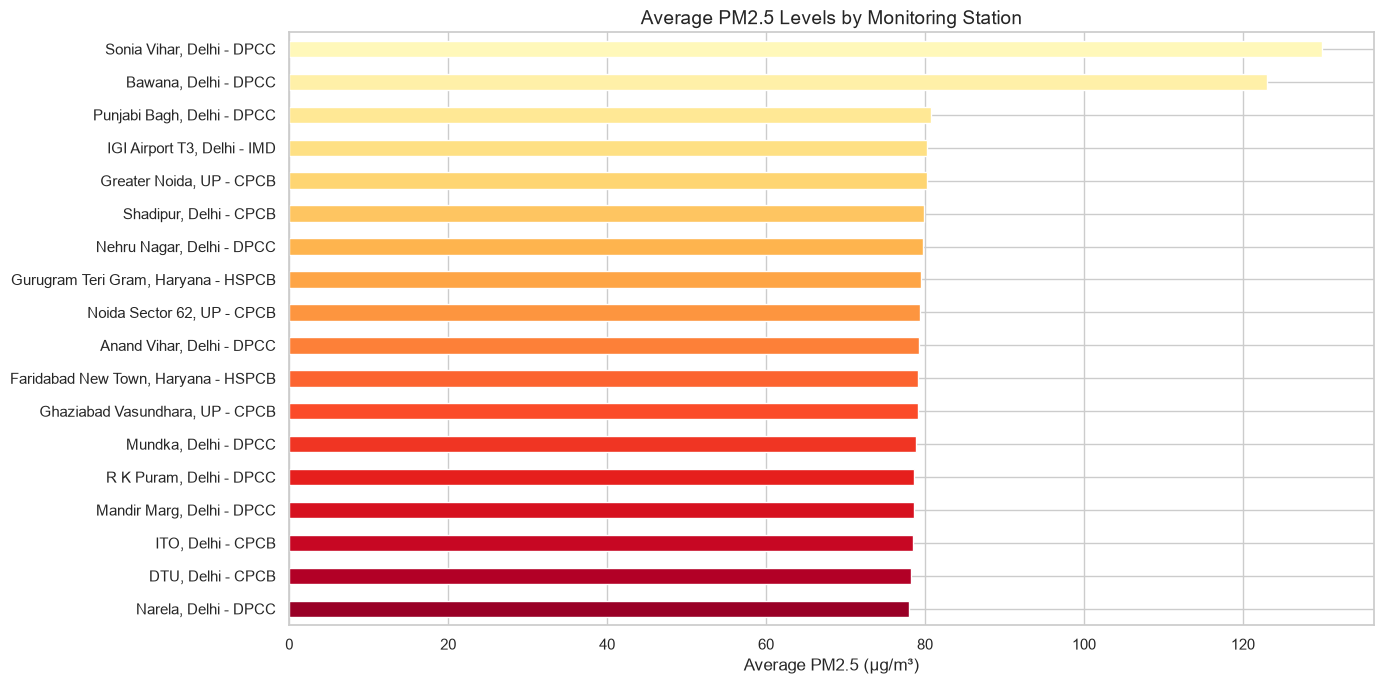

In [34]:
pm25 = df[df["pollutant_id"] == "PM2.5"].copy()
station_avg = (
    pm25.groupby("station")["avg_value"]
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(14, 7))
colors = sns.color_palette("YlOrRd", n_colors=len(station_avg))
station_avg.plot(kind="barh", ax=ax, color=colors)
ax.set_xlabel("Average PM2.5 (µg/m³)")
ax.set_ylabel("")
ax.set_title("Average PM2.5 Levels by Monitoring Station")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 7b. Distribution of PM2.5 Readings (Histogram)

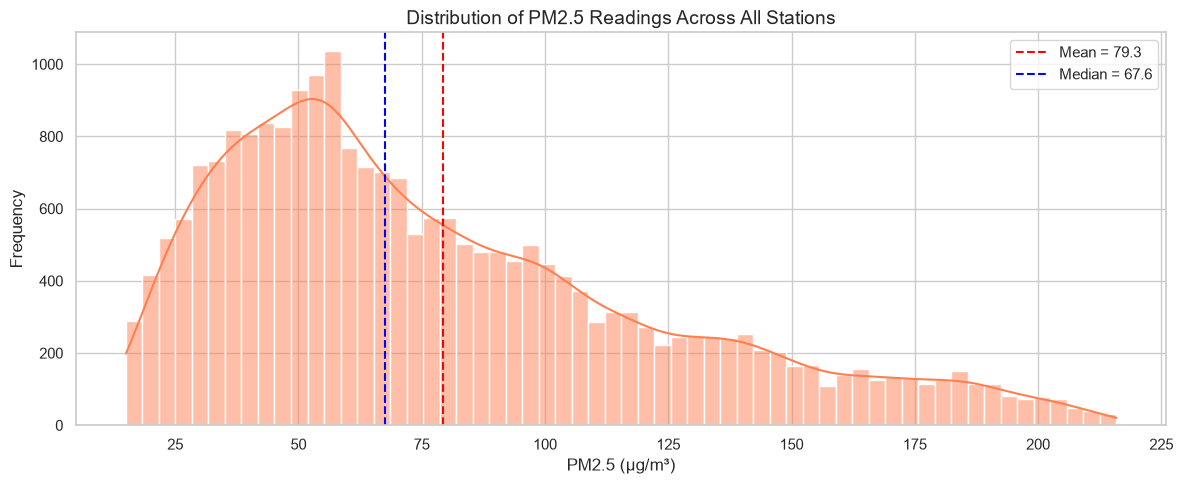

In [35]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(data=pm25, x="avg_value", bins=60, kde=True, color="coral", ax=ax)
ax.set_xlabel("PM2.5 (µg/m³)")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of PM2.5 Readings Across All Stations")
ax.axvline(pm25["avg_value"].mean(), color="red", linestyle="--", label=f"Mean = {pm25['avg_value'].mean():.1f}")
ax.axvline(pm25["avg_value"].median(), color="blue", linestyle="--", label=f"Median = {pm25['avg_value'].median():.1f}")
ax.legend()
plt.tight_layout()
plt.show()

In [36]:

df.sample()

,id,station,last_update,pollutant_id,avg_value
126987,126990,"Nehru Nagar, Delhi - DPCC",2026-07-21 12:00:00,PM10,84.3


---

**Next Steps:**
- Time-series analysis of pollutant trends
- Seasonal decomposition
- Correlation between pollutants
- Forecasting models